# Iteration 1: Unimodal Temporal Transformer

This notebook is the first PyTorch sequence model for the project.
It keeps the same 4-class task and the same subject-wise folds, but now uses the full time axis instead of handcrafted aggregate features.

Inputs:
- raw aligned tabular values
- missing-data masks
- delta-time features
- gaze and vehicle/control signals only

This notebook does not use front video yet. That comes in Iteration 2.

In [1]:
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "dataset" / "README.md").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root containing dataset/README.md.")

root = find_project_root(Path.cwd().resolve())
dbm_repo = root / "dataset"
data_dir = root / "data" / "IDD"

version = "no-video"
# version = "only-scaled-rgb-video"

target_fps = 10
chunk_duration_s = 30.0
chunks_per_scenario = 1
rebuild_window_cache = False
progress_every = 25

artifact_dir = root / "artifacts" / "temporal_transformer"
artifact_dir.mkdir(parents=True, exist_ok=True)
cache_dir = artifact_dir / "window_cache"

# Use full subject-wise cross-validation by default so the comparison with notebook 02b is fair.
run_all_folds = True
seed = 42

batch_size = 16
epochs = 30
patience = 8
learning_rate = 5e-4
# Iteration 2 tuning (see artifacts/temporal_transformer/sweep_results*.csv): stronger
# weight decay + dropout than the Iteration 1 default, chosen by 5-fold mean UAR.
weight_decay = 1e-3
normalize_inputs = True

model_dim = 64
num_heads = 4
num_layers = 1
ff_dim = 128
dropout = 0.3

# Class imbalance (alcohol_intoxication / combined have ~37-39 samples vs. ~147-148 for
# the other two classes -- see artifacts/logreg_baseline/per_class_report_all_models.csv)
# looks like the obvious thing to attack directly with focal loss + a per-batch class
# oversampler. We tried exactly that first; it was worse (UAR 0.32, see
# artifacts/temporal_transformer/all_folds_v1_focal_sampler/ and
# artifacts/temporal_transformer/sweep_results.csv). At ~220-230 training rows per fold,
# oversampling the ~35-40 minority rows up to parity means the model sees the same
# handful of examples many times per epoch and overfits to them -- precision on the
# minority classes collapsed even though recall went up. Plain class-weighted
# cross-entropy with no sampler, otherwise same architecture, recovered UAR 0.39 (best
# config in the sweep). Model *capacity* (dim/layers) turned out not to be the lever --
# smaller models in the sweep did not do better; the sampler was the whole story.
loss_type = "ce"  # "ce" or "focal" -- see note above, "ce" (no sampler) is the sweep winner
focal_gamma = 2.0
use_weighted_sampler = False

root

WindowsPath('C:/projects/DriverStateNet')

In [2]:
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

for name in list(sys.modules):
    if name == "data" or name.startswith("data."):
        sys.modules.pop(name, None)
    if name == "hail_datasets" or name.startswith("hail_datasets."):
        sys.modules.pop(name, None)

import src.data_bootstrap as data_bootstrap
import src.temporal_transformer as temporal_transformer

importlib.reload(data_bootstrap)
importlib.reload(temporal_transformer)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
np.set_printoptions(suppress=True)

## 1. PyTorch Check

This notebook needs a working local PyTorch install.
If the next cell fails, the dataset pipeline is still fine, but the Python environment needs to be fixed before training can run.

In [3]:
temporal_transformer.require_torch()
torch = temporal_transformer.torch
device = temporal_transformer.choose_device(prefer_cuda=True)

print(f"Torch version: {torch.__version__}")
print(f"Device: {device}")

Torch version: 2.11.0+cu128
Device: cuda


## 2. Load the Dataset and Build Temporal Windows

We reuse the same driving scenarios and fixed participant folds from the baseline notebooks.
The main difference is that we now keep the full aligned time window.

In [4]:
processed_root = data_bootstrap.ensure_processed_dataset(
    dbm_repo=dbm_repo,
    processed_root=data_dir,
    version=version,
    download_if_missing=False,
    prompt_for_license=False,
)

manifest_path = root / "artifacts" / "bootstrap" / "scenario_manifest.csv"
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    print(f"Loaded manifest from {manifest_path}")
else:
    manifest = data_bootstrap.build_scenario_manifest(
        dbm_repo=dbm_repo,
        processed_root=processed_root,
        scenario_name_filter=r"driving/[0-9].*",
    )
    manifest_path = artifact_dir / "scenario_manifest.csv"
    manifest.to_csv(manifest_path, index=False)
    print(f"Built and saved manifest to {manifest_path}")

inspection_dataset = data_bootstrap.build_inspection_dataset(
    dbm_repo=dbm_repo,
    processed_root=processed_root,
    scenario_name_filter=r"driving/[0-9].*",
    chunk_strategy="end",
    chunk_duration_s=chunk_duration_s,
    chunks_per_scenario=chunks_per_scenario,
    chunk_end_offset_s=0.0,
    include_video=False,
)

print(f"Dataset length: {len(inspection_dataset)}")

Loaded manifest from C:\projects\DriverStateNet\artifacts\bootstrap\scenario_manifest.csv


chunk_fps not specified - using max feature frame rate of 60.


Constructed dataset contains 52 participants, 371 scenarios, and 371 chunks.
Dataset length: 371


In [5]:
if (cache_dir / "window_cache.npz").exists() and not rebuild_window_cache:
    window_cache = temporal_transformer.load_temporal_window_cache(cache_dir)
    print(f"Loaded cached temporal windows from {cache_dir}")
else:
    window_cache = temporal_transformer.build_temporal_window_cache(
        inspection_dataset,
        manifest=manifest,
        target_fps=target_fps,
        progress_every=progress_every,
    )
    temporal_transformer.save_temporal_window_cache(window_cache, cache_dir)
    print(f"Saved temporal windows to {cache_dir}")

display(temporal_transformer.temporal_cache_summary(window_cache))

Loaded cached temporal windows from C:\projects\DriverStateNet\artifacts\temporal_transformer\window_cache


,num_samples,sequence_length,num_features,num_participants,num_folds,target_fps
0,371,300,84,52,5,10


impairment_label,baseline,cognitive_distraction,alcohol_intoxication,combined
fixed_fold,,,,
0,35,32,8,7
1,28,29,7,8
2,25,29,8,8
3,27,28,8,8
4,33,29,6,8


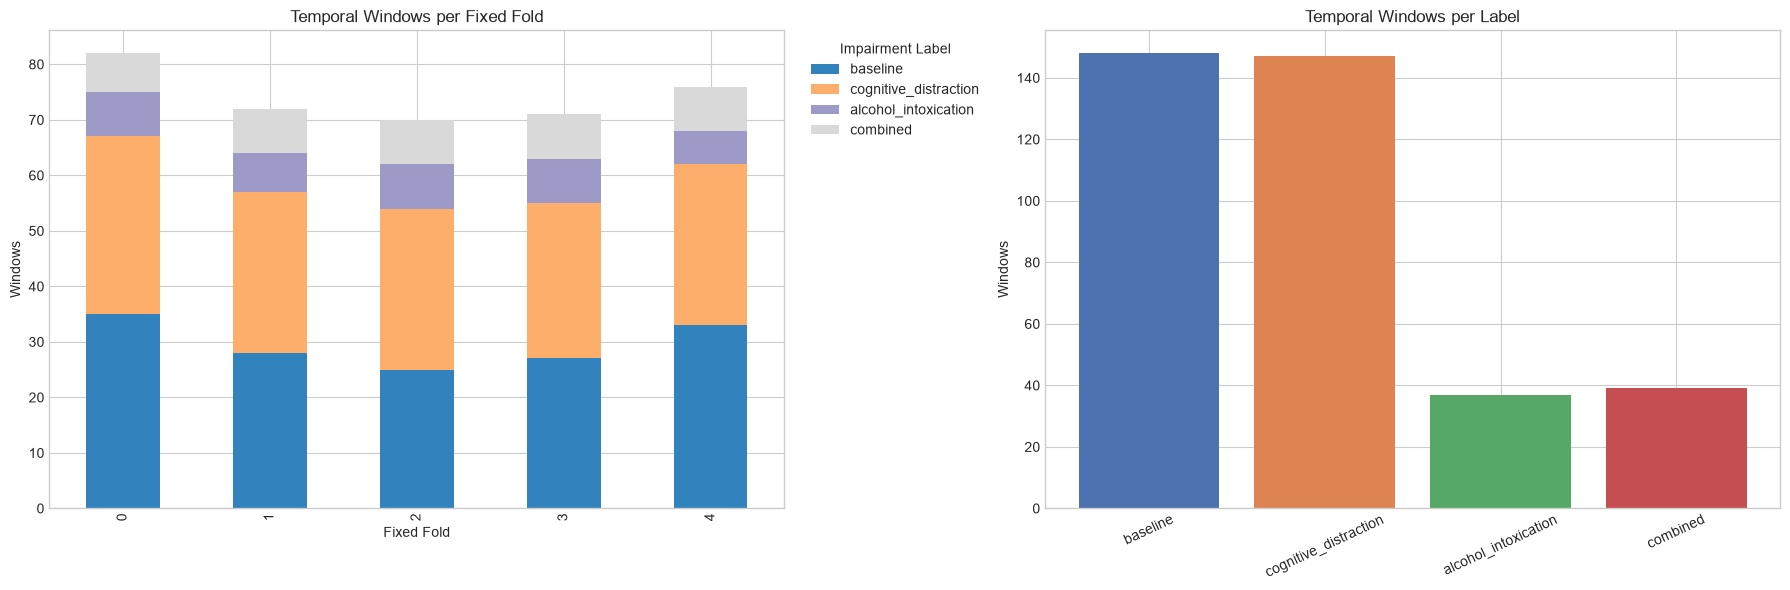

In [6]:
metadata = window_cache["metadata"].copy()
fold_label_counts = pd.crosstab(
    metadata["fixed_fold"],
    metadata["impairment_label"],
).reindex(columns=data_bootstrap.LABEL_ORDER, fill_value=0)

display(fold_label_counts)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

fold_label_counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20c")
axes[0].set_title("Temporal Windows per Fixed Fold")
axes[0].set_xlabel("Fixed Fold")
axes[0].set_ylabel("Windows")
axes[0].legend(title="Impairment Label", bbox_to_anchor=(1.02, 1), loc="upper left")

label_counts = metadata["impairment_label"].value_counts().reindex(data_bootstrap.LABEL_ORDER, fill_value=0)
axes[1].bar(label_counts.index, label_counts.values, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
axes[1].set_title("Temporal Windows per Label")
axes[1].set_xlabel("")
axes[1].set_ylabel("Windows")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(artifact_dir / "window_balance.png", dpi=150, bbox_inches="tight")

In [7]:
print("Tensor shape [N, T, F]:", window_cache["x"].shape)
print("Valid-mask shape [N, T]:", window_cache["valid_mask"].shape)
print("First 12 feature names:")
display(pd.Series(window_cache["feature_names"][:12], name="feature_name"))

Tensor shape [N, T, F]: (371, 300, 84)
Valid-mask shape [N, T]: (371, 300)
First 12 feature names:


0     ego_tracks__carla_objects_pose_x__delta_s
1        ego_tracks__carla_objects_pose_x__mask
2       ego_tracks__carla_objects_pose_x__value
3     ego_tracks__carla_objects_pose_y__delta_s
4        ego_tracks__carla_objects_pose_y__mask
5       ego_tracks__carla_objects_pose_y__value
6     ego_tracks__lateral_acceleration__delta_s
7        ego_tracks__lateral_acceleration__mask
8       ego_tracks__lateral_acceleration__value
9             ego_tracks__lateral_jerk__delta_s
10               ego_tracks__lateral_jerk__mask
11              ego_tracks__lateral_jerk__value
Name: feature_name, dtype: str

## 3. Train the Temporal Transformer

For stable early stopping, each run uses:
- one held-out fold for testing
- one separate fixed fold for validation
- the remaining folds for training

In [8]:
available_folds = sorted(metadata["fixed_fold"].astype(int).unique().tolist())
folds_to_run = available_folds if run_all_folds else [available_folds[0]]

print("Available folds:", available_folds)
print("Folds to run:", folds_to_run)

Available folds: [0, 1, 2, 3, 4]
Folds to run: [0, 1, 2, 3, 4]


In [9]:
temporal_results = temporal_transformer.run_fixed_fold_temporal_experiment(
    cache=window_cache,
    folds_to_run=folds_to_run,
    batch_size=batch_size,
    epochs=epochs,
    patience=patience,
    lr=learning_rate,
    weight_decay=weight_decay,
    model_dim=model_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    ff_dim=ff_dim,
    dropout=dropout,
    normalize_inputs=normalize_inputs,
    loss_type=loss_type,
    focal_gamma=focal_gamma,
    use_weighted_sampler=use_weighted_sampler,
    device=device,
    seed=seed,
    label_names=data_bootstrap.LABEL_ORDER,
)

run_name = "all_folds" if run_all_folds else f"held_out_fold_{folds_to_run[0]}"
run_dir = artifact_dir / run_name
run_dir.mkdir(parents=True, exist_ok=True)

temporal_results["fold_metrics"].to_csv(run_dir / "fold_metrics.csv", index=False)
temporal_results["predictions"].to_csv(run_dir / "predictions.csv", index=False)
temporal_results["history"].to_csv(run_dir / "history.csv", index=False)
temporal_results["overall_metrics"].to_csv(run_dir / "overall_metrics.csv", header=["value"])
temporal_results["overall_confusion"].to_csv(run_dir / "overall_confusion.csv")
temporal_results["per_class_report"].to_csv(run_dir / "per_class_report.csv")

display(temporal_results["fold_metrics"])
display(temporal_results["overall_metrics"].to_frame("value"))
display(temporal_results["per_class_report"])

Running temporal transformer for held-out fold 0


C:\projects\DriverStateNet\src\temporal_transformer.py:264: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Running temporal transformer for held-out fold 1


C:\projects\DriverStateNet\src\temporal_transformer.py:264: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Running temporal transformer for held-out fold 2


C:\projects\DriverStateNet\src\temporal_transformer.py:264: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


... (3 outputs left out)

C:\projects\DriverStateNet\src\temporal_transformer.py:264: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


,model_name,fixed_fold,validation_fold,num_train,num_val,num_test,best_epoch,normalize_inputs,loss_type,use_weighted_sampler,uar,precision_macro,recall_macro,f1_macro,accuracy
0,temporal_transformer,0,1,217,72,82,5,True,ce,False,0.483036,0.448142,0.483036,0.434689,0.475610
1,temporal_transformer,1,2,229,70,72,19,True,ce,False,0.393319,0.429386,0.393319,0.386921,0.541667
2,temporal_transformer,2,3,230,71,70,15,True,ce,False,0.428664,0.448524,0.428664,0.427747,0.500000
3,temporal_transformer,3,4,224,76,71,21,True,ce,False,0.321925,0.524306,0.321925,0.335427,0.464789
4,temporal_transformer,4,0,213,82,76,2,True,ce,False,0.353056,0.327804,0.353056,0.293469,0.315789


,value
model_name,temporal_transformer
uar,0.390666
precision_macro,0.386839
recall_macro,0.390666
f1_macro,0.384406
accuracy,0.458221
num_samples,371
num_features,84
sequence_length,300
num_folds,5


,precision,recall,f1,support
baseline,0.586777,0.479730,0.527881,148
cognitive_distraction,0.520000,0.530612,0.525253,147
alcohol_intoxication,0.263158,0.270270,0.266667,37
combined,0.177419,0.282051,0.217822,39


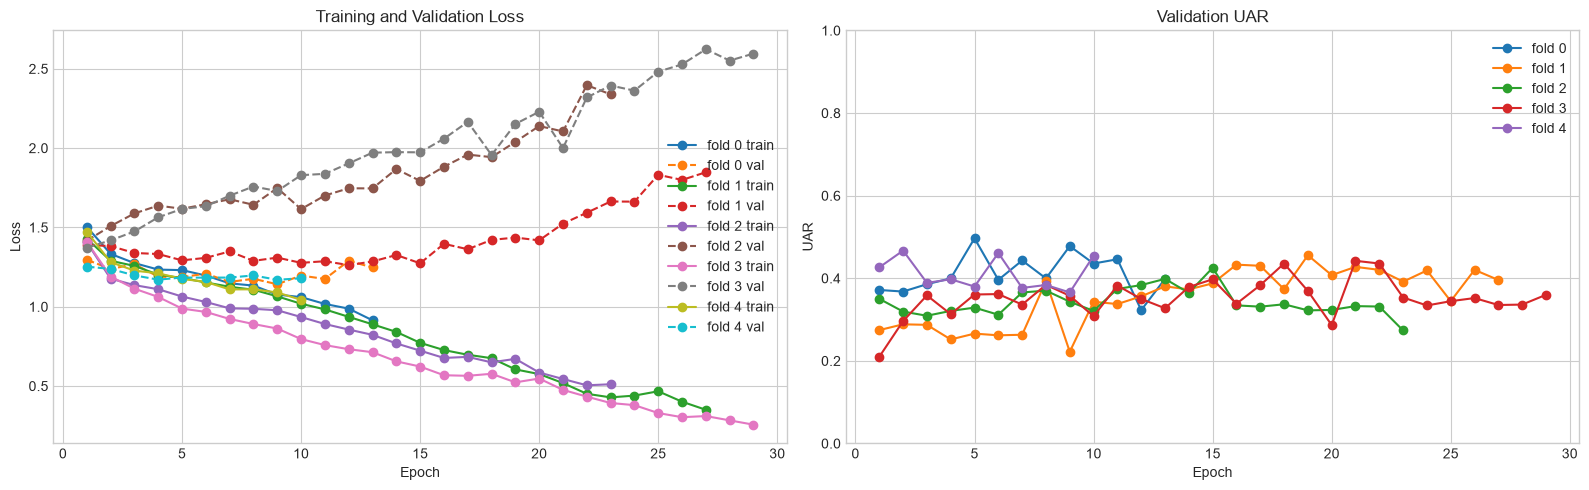

In [10]:
history = temporal_results["history"].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for fixed_fold in sorted(history["fixed_fold"].unique()):
    fold_history = history.loc[history["fixed_fold"] == fixed_fold].sort_values("epoch")
    axes[0].plot(
        fold_history["epoch"],
        fold_history["train_loss"],
        marker="o",
        label=f"fold {fixed_fold} train",
    )
    axes[0].plot(
        fold_history["epoch"],
        fold_history["val_loss"],
        marker="o",
        linestyle="--",
        label=f"fold {fixed_fold} val",
    )
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=10)

for fixed_fold in sorted(history["fixed_fold"].unique()):
    fold_history = history.loc[history["fixed_fold"] == fixed_fold].sort_values("epoch")
    axes[1].plot(
        fold_history["epoch"],
        fold_history["val_uar"],
        marker="o",
        label=f"fold {fixed_fold}",
    )
axes[1].set_title("Validation UAR")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("UAR")
axes[1].set_ylim(0.0, 1.0)
axes[1].legend(fontsize=10)

fig.tight_layout()
fig.savefig(run_dir / "training_curves.png", dpi=150, bbox_inches="tight")

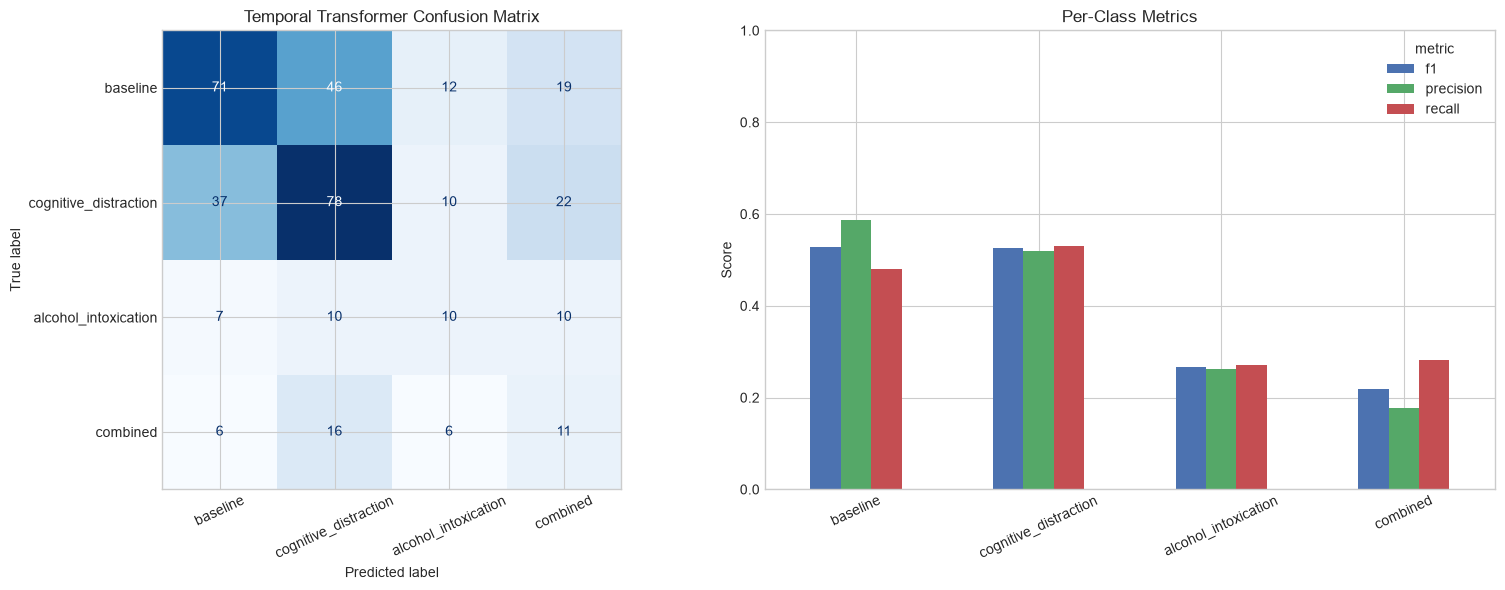

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=temporal_results["overall_confusion"].to_numpy(),
    display_labels=temporal_results["overall_confusion"].index.to_list(),
)
confusion_display.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Temporal Transformer Confusion Matrix")
axes[0].tick_params(axis="x", rotation=25)

per_class = temporal_results["per_class_report"].reset_index().rename(columns={"index": "label"})
per_class_plot = per_class.melt(
    id_vars=["label", "support"],
    value_vars=["precision", "recall", "f1"],
    var_name="metric",
    value_name="score",
)
pivot = per_class_plot.pivot(index="label", columns="metric", values="score").reindex(
    temporal_results["overall_confusion"].index.to_list()
)
pivot.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#55A868", "#C44E52"])
axes[1].set_title("Per-Class Metrics")
axes[1].set_xlabel("")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.0, 1.0)
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(title="metric")

fig.tight_layout()
fig.savefig(run_dir / "evaluation_summary.png", dpi=150, bbox_inches="tight")

## 4. Optional Comparison with the Classical Baseline

If notebook 02b has already been run, we can compare the temporal transformer against the saved handcrafted baseline.

,uar,precision_macro,f1_macro,accuracy
model_name,,,,
logistic_regression,0.439852,0.421643,0.423321,0.498652
linear_svm,0.417289,0.413427,0.412842,0.517520
temporal_transformer,0.390666,0.386839,0.384406,0.458221


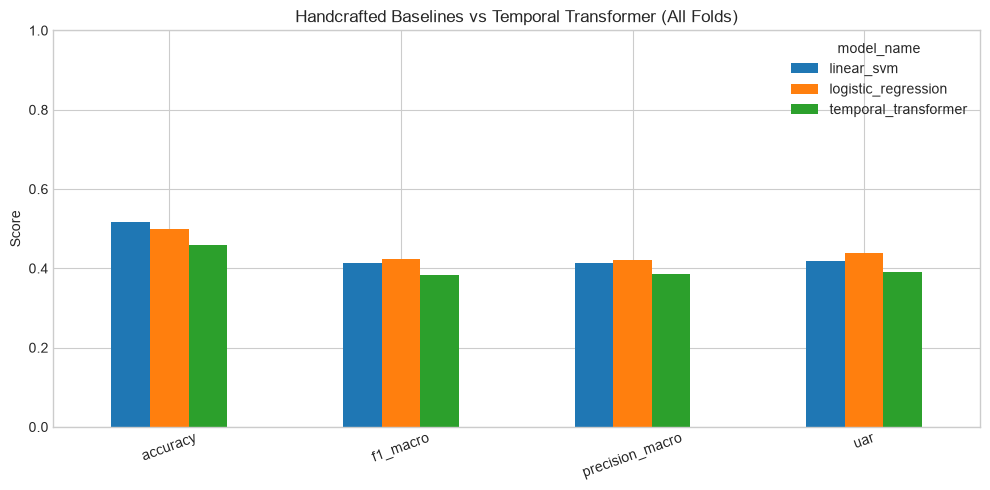

In [12]:
handcrafted_dir = root / "artifacts" / "handcrafted_baseline"
logistic_fold_path = handcrafted_dir / "logistic_regression" / "fold_metrics.csv"
svm_fold_path = handcrafted_dir / "linear_svm" / "fold_metrics.csv"
baseline_path = handcrafted_dir / "model_comparison.csv"
comparison = None
title = None

if run_all_folds and baseline_path.exists():
    baseline_metrics = pd.read_csv(baseline_path, index_col=0)
    temporal_row = pd.DataFrame([temporal_results["overall_metrics"].to_dict()]).set_index("model_name")
    comparison = pd.concat(
        [
            baseline_metrics[["uar", "precision_macro", "f1_macro", "accuracy"]],
            temporal_row[["uar", "precision_macro", "f1_macro", "accuracy"]],
        ]
    )
    title = "Handcrafted Baselines vs Temporal Transformer (All Folds)"
elif (
    not run_all_folds
    and logistic_fold_path.exists()
    and svm_fold_path.exists()
):
    held_out_fold = int(folds_to_run[0])
    logistic_fold_metrics = pd.read_csv(logistic_fold_path)
    svm_fold_metrics = pd.read_csv(svm_fold_path)
    baseline_folds = pd.concat([logistic_fold_metrics, svm_fold_metrics], ignore_index=True)
    baseline_folds = baseline_folds.loc[baseline_folds["fixed_fold"] == held_out_fold].copy()
    comparison = pd.concat(
        [
            baseline_folds.set_index("model_name")[["uar", "precision_macro", "f1_macro", "accuracy"]],
            temporal_results["fold_metrics"].set_index("model_name")[["uar", "precision_macro", "f1_macro", "accuracy"]],
        ]
    )
    title = f"Handcrafted Baselines vs Temporal Transformer (Held-Out Fold {held_out_fold})"
else:
    print("Handcrafted baseline comparison file not found. Run notebook 02b first if you want this comparison.")

if comparison is not None:
    display(comparison)

    comparison_plot = comparison.reset_index().melt(
        id_vars="model_name",
        var_name="metric",
        value_name="score",
    )
    comparison_pivot = comparison_plot.pivot(index="metric", columns="model_name", values="score")
    ax = comparison_pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.set_ylim(0.0, 1.0)
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.savefig(run_dir / "baseline_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()